In [9]:
%%time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ROPA import RateOfProductionAnalysis

pathkin = 'C:\\Users\\timot\\Desktop\\Example_ROPA_AMN\\TOT2110_soot_last\\'
outxml = 'C:\\Users\\timot\\Desktop\\Example_ROPA_AMN\\Sun2017_RCM_AMN\\output\\Case0\\'

suca = RateOfProductionAnalysis(pathkin, outxml, 'C10H10')
C, P = suca.ComputeRopa(Type = 'Global')

Wall time: 22.6 s


In [10]:
nonzero_P = np.nonzero(P)[0] 
nonzero_C = np.nonzero(C)[0]
ROPA_results = {'id_P': [], 'P_reactions': [], 'ROPA_Coeff_P': [],'id_C': [],
                'C_reactions': [], 'ROPA_Coeff_C': []}

if len(nonzero_P) != 0:
    for i in nonzero_P:
        ROPA_results['id_P'].append(i)
        ROPA_results['P_reactions'].append(suca.reactionsNames[i])
        ROPA_results['ROPA_Coeff_P'].append(P[i])

if len(nonzero_C) != 0:
    for j in nonzero_C:

        ROPA_results['id_C'].append(j)
        ROPA_results['C_reactions'].append(suca.reactionsNames[j])
        ROPA_results['ROPA_Coeff_C'].append(-C[j])
# print(ROPA_results)

ROPA_results_plot = {'Reactions': [], 'Coefficients': []}
ROPA_results_plot['Reactions'].append(ROPA_results['P_reactions'] + ROPA_results['C_reactions'])
ROPA_results_plot['Coefficients'].append(ROPA_results['ROPA_Coeff_P'] + ROPA_results['ROPA_Coeff_C'])

ROPA_results_plot['Reactions'] = ROPA_results_plot['Reactions'][0]
ROPA_results_plot['Coefficients'] = ROPA_results_plot['Coefficients'][0]

# print(ROPA_results_plot)


df = pd.DataFrame.from_dict(ROPA_results_plot)
df['Coefficients_abs'] = abs(df['Coefficients'])
df = df.sort_values(by=['Coefficients_abs'])

df_last_15 = df.iloc[-15:]
df_last_15

,Reactions,Coefficients,Coefficients_abs
15,CH3+C10H10=>H+CH4+C10H8,-1.170370e-08,1.170370e-08
2,2C6H5O=>2CO+C10H10,1.274209e-08,1.274209e-08
4,O2+RTETRALIN=>HO2+C10H10,3.188094e-08,3.188094e-08
33,HO2+C10H10=>H+H2O2+C10H8,-3.822737e-08,3.822737e-08
13,OH+C10H10=>H+C2H4+BZFUR,-4.302525e-08,4.302525e-08
10,H+C10H10=>RTETRALIN,-6.328618e-08,6.328618e-08
6,RTETRAOO=>HO2+C10H10,1.343426e-07,1.343426e-07
11,OH+C10H10=>C2H3CHO+CH3C6H4,-1.982055e-07,1.982055e-07
12,OH+C10H10=>CH3CHO+C6H5C2H2,-1.982055e-07,1.982055e-07
9,C10H10=>H2+C10H8,-3.353493e-07,3.353493e-07


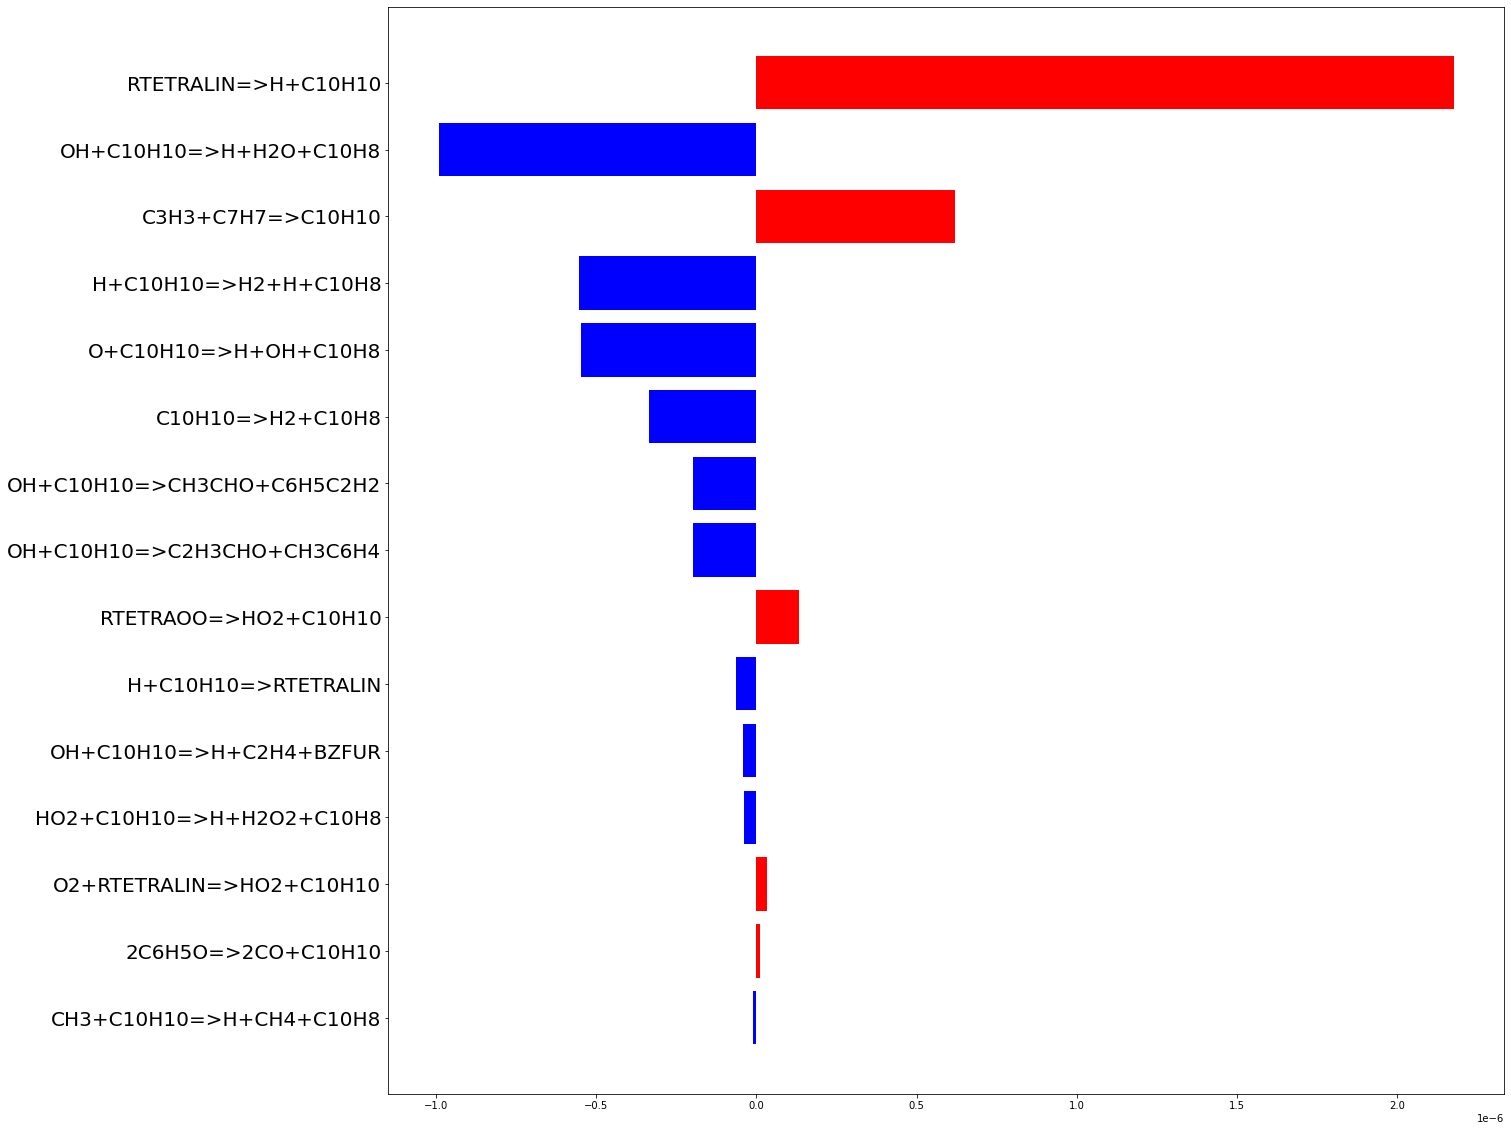

In [12]:
df = df_last_15
plt.rcParams["figure.figsize"]=20,20
plt.barh(df['Reactions'], df['Coefficients'], color = (df['Coefficients'] >=0.).map({True:'red', False:'blue'}))

plt.yticks(fontsize = 20)
plt.xticks(fontsize = 10)

plt.show()